# 03. Expected and Unexpected Rate Changes (Kuttner 2001)

Notebook 02 used one day's ZQ prices to ask what the market expects the
FOMC to do. This notebook turns the question around: on the day the FOMC
announces, how much of its decision was news?

[Kuttner (2001)](https://doi.org/10.1016/S0304-3932(01)00055-1) splits
each change in the fed funds target into an expected part and a surprise,
using the one-day change in fed funds futures, and asks which part moves
Treasury yields. If bond markets look ahead, the expected part is already
in yields before the meeting, so yields should respond to the surprise and
barely to the expected part. His sample covers 1989 to 2000. Here we apply
the same measure to every FOMC announcement since June 2010, the start of
Databento's CME Globex history.

The computation lives in `src/calc_kuttner_surprises.py` and runs as the
`calc_kuttner` doit task; this notebook loads its output.

## Measuring the surprise

The current-month ZQ contract settles at 100 minus the month's average fed
funds rate, so $f = 100 - P$ is the market's forecast of that average. If
the decision is announced on day $d$ of a $D$-day month, the new rate is in
force for the remaining $D - d$ days. An unexpected change of $x$ moves
the monthly average by $x \cdot (D-d)/D$, so the surprise is

$$ \Delta r^u = \frac{D}{D-d}\,\left(f_{d} - f_{d-1}\right). $$

The expected part is whatever is left of the actual change in the target:
$\Delta r^e = \Delta \bar r - \Delta r^u$.

Two details:

- Late in the month $D/(D-d)$ is large and multiplies any noise in the
  price. For announcements in the last seven days of a month, we use the
  change in the *next* month's contract, which the decision affects for
  the whole month, with no scaling.
- Databento's daily bars cover UTC days, so the close on announcement day
  is a trade from the evening, after the 2 p.m. ET statement, and the
  previous bar's close is from before it. The Sunday-evening Globex
  session has its own bar, which is how the Sunday, March 15, 2020 cut is
  measured.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from calc_kuttner_surprises import load_kuttner_events, load_kuttner_regressions

events = load_kuttner_events()
regressions = load_kuttner_regressions()
print(
    f"{len(events)} announcements, "
    f"{events['announcement_date'].min():%B %Y} to {events['announcement_date'].max():%B %Y}; "
    f"{(events['target_change'] != 0).sum()} changed the target"
)

132 announcements, June 2010 to September 2026; 32 changed the target


## Every target change since 2010

The table lists the announcements that moved the target range, all in
basis points. `delta_f` is the one-day change in the contract's implied
rate and `scale` is $D/(D-d)$ (1 when the next month's contract is used).

In [2]:
cols = [
    "announcement_date",
    "contract_month",
    "scale",
    "delta_f",
    "target_change",
    "surprise",
    "expected",
]
changes = events.loc[events["target_change"] != 0, cols]
changes.style.format(
    {
        "announcement_date": "{:%Y-%m-%d}",
        "scale": "{:.2f}",
        "delta_f": "{:.1f}",
        "target_change": "{:.0f}",
        "surprise": "{:.1f}",
        "expected": "{:.1f}",
    }
).hide(axis="index")

announcement_date,contract_month,scale,delta_f,target_change,surprise,expected
2015-12-16,2015-12,2.07,1.0,25,2.1,22.9
2016-12-14,2016-12,1.82,-0.2,25,-0.5,25.5
2017-03-15,2017-03,1.94,0.2,25,0.5,24.5
2017-06-14,2017-06,1.88,0.5,25,0.9,24.1
2017-12-13,2017-12,1.72,0.2,25,0.4,24.6
2018-03-21,2018-03,3.10,0.2,25,0.8,24.2
2018-06-13,2018-06,1.76,-0.3,25,-0.4,25.4
2018-09-26,2018-10,1.00,-0.0,25,-0.0,25.0
2018-12-19,2018-12,2.58,1.3,25,3.2,21.8
2019-07-31,2019-08,1.00,4.3,-25,4.3,-29.3


Most moves were almost fully expected. The surprise is a few basis points
at most, except the two emergency cuts of March 2020 and the 50 bp cut of
September 2024. The expected part of that cut, about 39 bp, says the
market saw it as a close call between 25 and 50 bp.

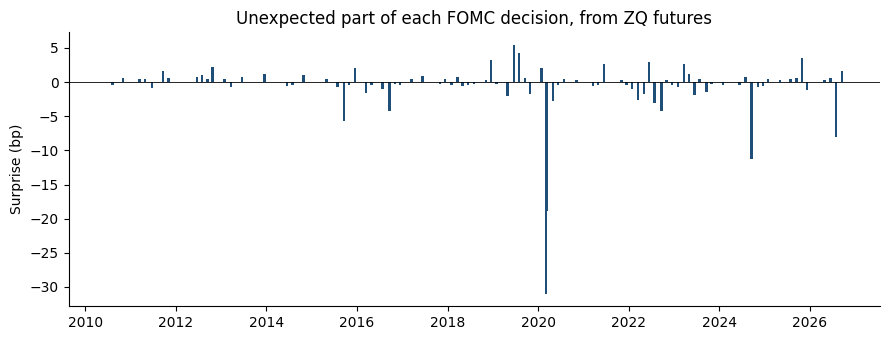

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(events["announcement_date"], events["surprise"], width=20, color="#1f4e79")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_ylabel("Surprise (bp)")
ax.set_title("Unexpected part of each FOMC decision, from ZQ futures")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()

## How Treasury yields respond

For each GSW zero-coupon maturity we regress the one-day yield change on
the target change, and then on its two parts:

$$ \Delta y_n = a + b^e\,\Delta r^e + b^u\,\Delta r^u + \varepsilon. $$

Standard errors are heteroskedasticity-robust (HC1). The table reports the
slopes with $t$-statistics in parentheses, for every announcement and
without the two March 2020 emergency cuts, which came in the middle of a
market crash.

In [4]:
slopes = regressions[regressions["regressor"] != "const"].copy()
slopes["cell"] = slopes.apply(lambda r: f"{r['coef']:.2f} ({r['t']:.1f})", axis=1)
table = slopes.pivot_table(
    index=["sample", "spec", "regressor"],
    columns="maturity",
    values="cell",
    aggfunc="first",
)
table.columns = [f"{n}y" for n in table.columns]
nobs = regressions.groupby("sample")["nobs"].first()
print(nobs.to_string())
table

sample
all                132
excl_march_2020    130


1y            2y  \
sample          spec       regressor                                   
all             decomposed expected       -0.05 (-1.7)  -0.03 (-0.6)   
                           surprise         0.38 (3.8)    0.34 (2.7)   
                target     target_change  -0.02 (-0.6)  -0.00 (-0.1)   
excl_march_2020 decomposed expected       -0.05 (-1.6)  -0.05 (-0.9)   
                           surprise         0.13 (0.6)  -0.09 (-0.3)   
                target     target_change  -0.05 (-1.6)  -0.05 (-0.9)   

                                                    5y           10y  \
sample          spec       regressor                                   
all             decomposed expected       -0.06 (-1.4)  -0.03 (-0.8)   
                           surprise         0.44 (2.3)    0.33 (1.7)   
                target     target_change  -0.03 (-0.5)  -0.00 (-0.0)   
excl_march_2020 decomposed expected       -0.09 (-2.5)  -0.06 (-2.3)   
                           surprise       -0.12 (-0.4)  -0.21 (-0.9)   
                target     target_change  -0.09 (-2.4)  -0.06 (-2.3)   

                                                   30y  
sample          spec       regressor                    
all             decomposed expected       -0.04 (-0.8)  
                           surprise         0.20 (0.7)  
                target     target_change  -0.02 (-0.4)  
excl_march_2020 decomposed expected       -0.08 (-2.8)  
                           surprise       -0.38 (-1.3)  
                target     target_change  -0.09 (-3.0)

With every announcement included, yields respond to the surprise: about a
third of a basis point per basis point of surprise, significant out to
five years and smaller at 30 years. The expected part has no significant
effect, as Kuttner found.

That result rests on the two March 2020 cuts. Without them, the surprise
has no significant effect at any maturity, and the expected part has a
small negative slope at five years and beyond: long yields fell slightly,
on average, on days the Fed delivered an expected hike. An expected hike
carries no news about the current rate, so whatever moved long yields on
those days was other news in the statement.

Outside March 2020, target surprises since 2010 have a standard deviation
of about 2 bp. The Fed now signals its moves in advance, so the news in a
statement is mostly about the future path of rates rather than the
current decision. This is the second factor in
[Gürkaynak, Sack, and Swanson (2005)](https://www.ijcb.org/journal/v1n1/do-actions-speak-louder-words-response-asset-prices-monetary-policy-actions-and),
and a one-day change in the current-month contract does not capture it.

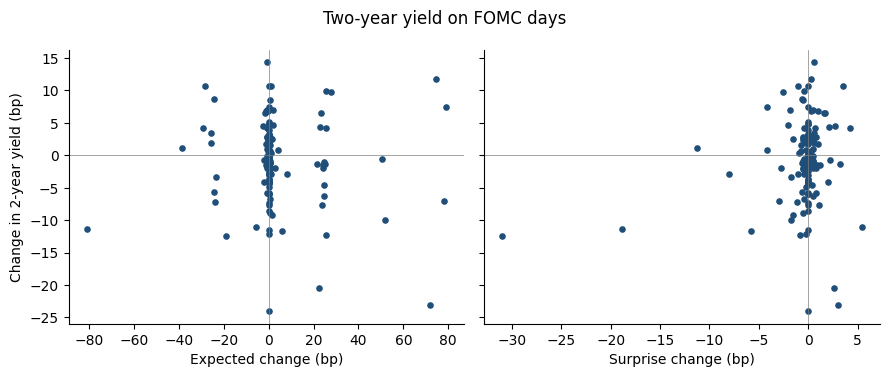

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, part in zip(axes, ["expected", "surprise"]):
    ax.scatter(events[part], events["dy_2y"], s=14, color="#1f4e79")
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_xlabel(f"{part.capitalize()} change (bp)")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
axes[0].set_ylabel("Change in 2-year yield (bp)")
fig.suptitle("Two-year yield on FOMC days")
fig.tight_layout()